In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
import pandas as pd

california = fetch_california_housing(as_frame=True)

# Configuramos el estilo de las gráficas para que se vean profesionales en clase
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# 1. GENERACIÓN DE DATOS (Ejemplo: California Housing)
# Tomamos por ejemplo el ingreso medio (MedInc) vs el valor de la casa (MedHouse)
X = california.data['MedInc'].values[:50]   # ingreso medio de 50 zonas
Y = california.target.values[:50]   # valor medio de las casas en esas zonas

print(f"Datos cargados con éxito: {len(X)} zonas analizadas.")

Datos cargados con éxito: 50 zonas analizadas.


In [2]:
# 2. INICIALIZACIÓN DE PARÁMETROS
w = 0.0
b = 0.0

# Hiperparámetros
learning_rate = 0.009 # Tasa de aprendizaje ajustada para esta escala
epochs = 1500         # Iteraciones de entrenamientoprint(np.polyfit(X, Y, 1))
n = len(X)

# Historial para graficar la evolución del costo si lo deseas mostrar
historial_costos = []

# 3. ENTRENAMIENTO
for epoch in range(epochs):
    # Predice la línea actual para cada zona
    Y_pred = w * X + b
    
    #  Costo, qué tan lejos quedan las predicciones de los valores reales
    cost = (1 / (2 * n)) * np.sum((Y_pred - Y) ** 2)
    historial_costos.append(cost)
    
    # Gradientes, hacia dónde y cuándo mover w y b para que el coste baje
    dw = (2 / n) * np.sum((Y_pred - Y) * X)
    db = (2 / n) * np.sum(Y_pred - Y)
    
    # Actualizar w y b con un paso pequeño, el learning_rate, en la dirección que baja el error
    w = w - learning_rate * dw
    b = b - learning_rate * db

print("¡Entrenamiento completado!")
print(f"Ecuación final aprendida: Valor de la casa = {w:.4f} * (Ingreso medio) + {b:.4f}")

¡Entrenamiento completado!
Ecuación final aprendida: Valor de la casa = 0.4418 * (Ingreso medio) + 0.6005


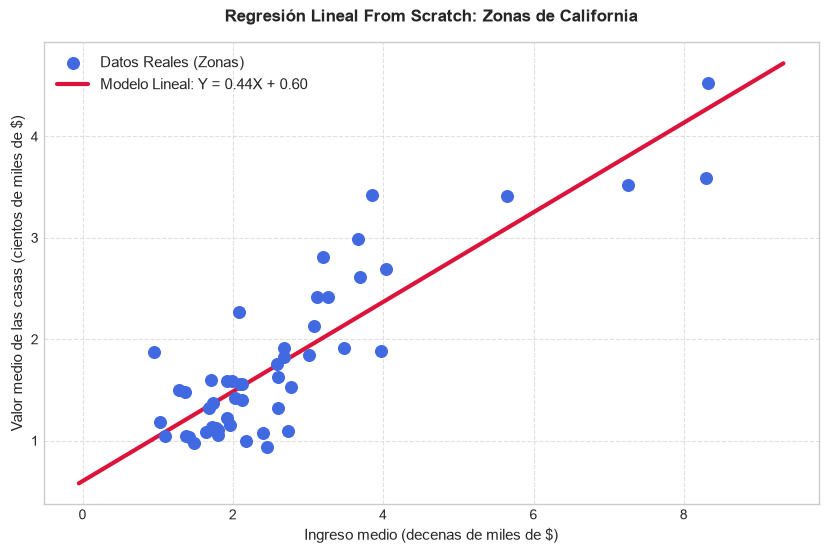

In [3]:
# 4. VISUALIZACIÓN DE RESULTADOS
plt.figure(figsize=(10, 6))

# Dibujar los puntos reales (Casas)
plt.scatter(X, Y, color='royalblue', s=70, label='Datos Reales (Zonas)', zorder=5)

# Dibujar la línea de tendencia aprendida por el modelo
X_linea = np.linspace(min(X) - 1, max(X) + 1, 100)
Y_linea = w * X_linea + b
plt.plot(X_linea, Y_linea, color='crimson', linewidth=3, label=f'Modelo Lineal: Y = {w:.2f}X + {b:.2f}')

# Etiquetas y formato estético
plt.title('Regresión Lineal From Scratch: Zonas de California', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Ingreso medio (decenas de miles de $)', fontsize=11)
plt.ylabel('Valor medio de las casas (cientos de miles de $)', fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

In [4]:
# Verificación: solución exacta para comparar con el modelo
print(np.polyfit(X, Y, 1))

[0.44159994 0.60116103]


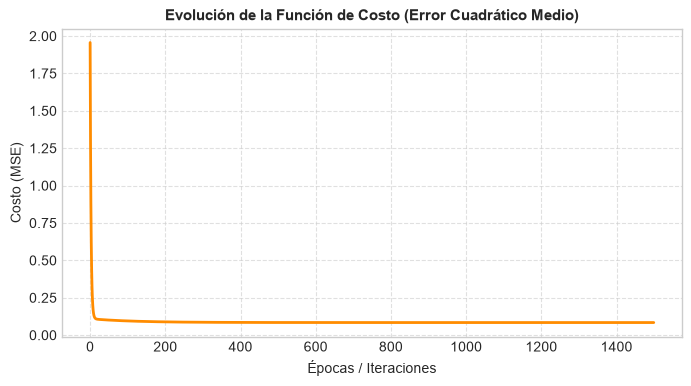

In [5]:
plt.figure(figsize=(8, 4))
plt.plot(range(epochs), historial_costos, color='darkorange', linewidth=2)
plt.title('Evolución de la Función de Costo (Error Cuadrático Medio)', fontsize=11, fontweight='bold')
plt.xlabel('Épocas / Iteraciones', fontsize=10)
plt.ylabel('Costo (MSE)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()